# 03 · Cohort retention, MAU, repeat trading and segmentation

> **All data in this notebook are synthetic** (fictional Indian retail brokerage, 10,000 users, Nov 2025 - Oct 2026, INR, snapshot 2026-10-31). No real company data are used.

Retention uses **calendar-month proxies** (M1 = active in the month after the registration month), not exact 30/90/180-day retention. 'Dormant 3m' and 'inactive 90d' are churn **proxies**.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from fintech_analytics import config as C, loading, cleaning, eda, funnel, campaign, cohort, segmentation, support, kpi_report
%matplotlib inline
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
d = loading.load_all(); users, act, tix, camp = d['users'], d['activity'], d['tickets'], d['campaigns']
print(f'users={len(users):,}  monthly rows={len(act):,}  tickets={len(tix):,}  campaigns={len(camp)}  (ALL DATA SYNTHETIC)')

users=10,000  monthly rows=64,645  tickets=7,614  campaigns=10  (ALL DATA SYNTHETIC)


## 1 · Cohort retention matrix

In [2]:
mat = cohort.retention_matrix(act); mat

,M0,M1,M2,M3,M4,M5,M6
registration_month,,,,,,,
2025-11,77.63,67.11,63.12,56.35,48.13,46.55,41.23
2025-12,76.48,66.78,62.21,55.71,47.49,44.29,40.75
2026-01,74.63,69.21,61.82,58.87,52.46,44.58,42.98
2026-02,74.02,64.26,59.32,53.74,50.06,45.75,40.68
2026-03,75.30,68.37,63.99,56.69,51.95,44.77,38.93
2026-04,75.51,66.71,64.90,54.04,49.70,45.11,39.69
2026-05,74.35,68.17,61.05,56.41,49.52,45.72,NaN
2026-06,79.92,69.00,61.37,56.42,48.16,NaN,NaN
2026-07,76.35,67.41,61.18,55.88,NaN,NaN,NaN


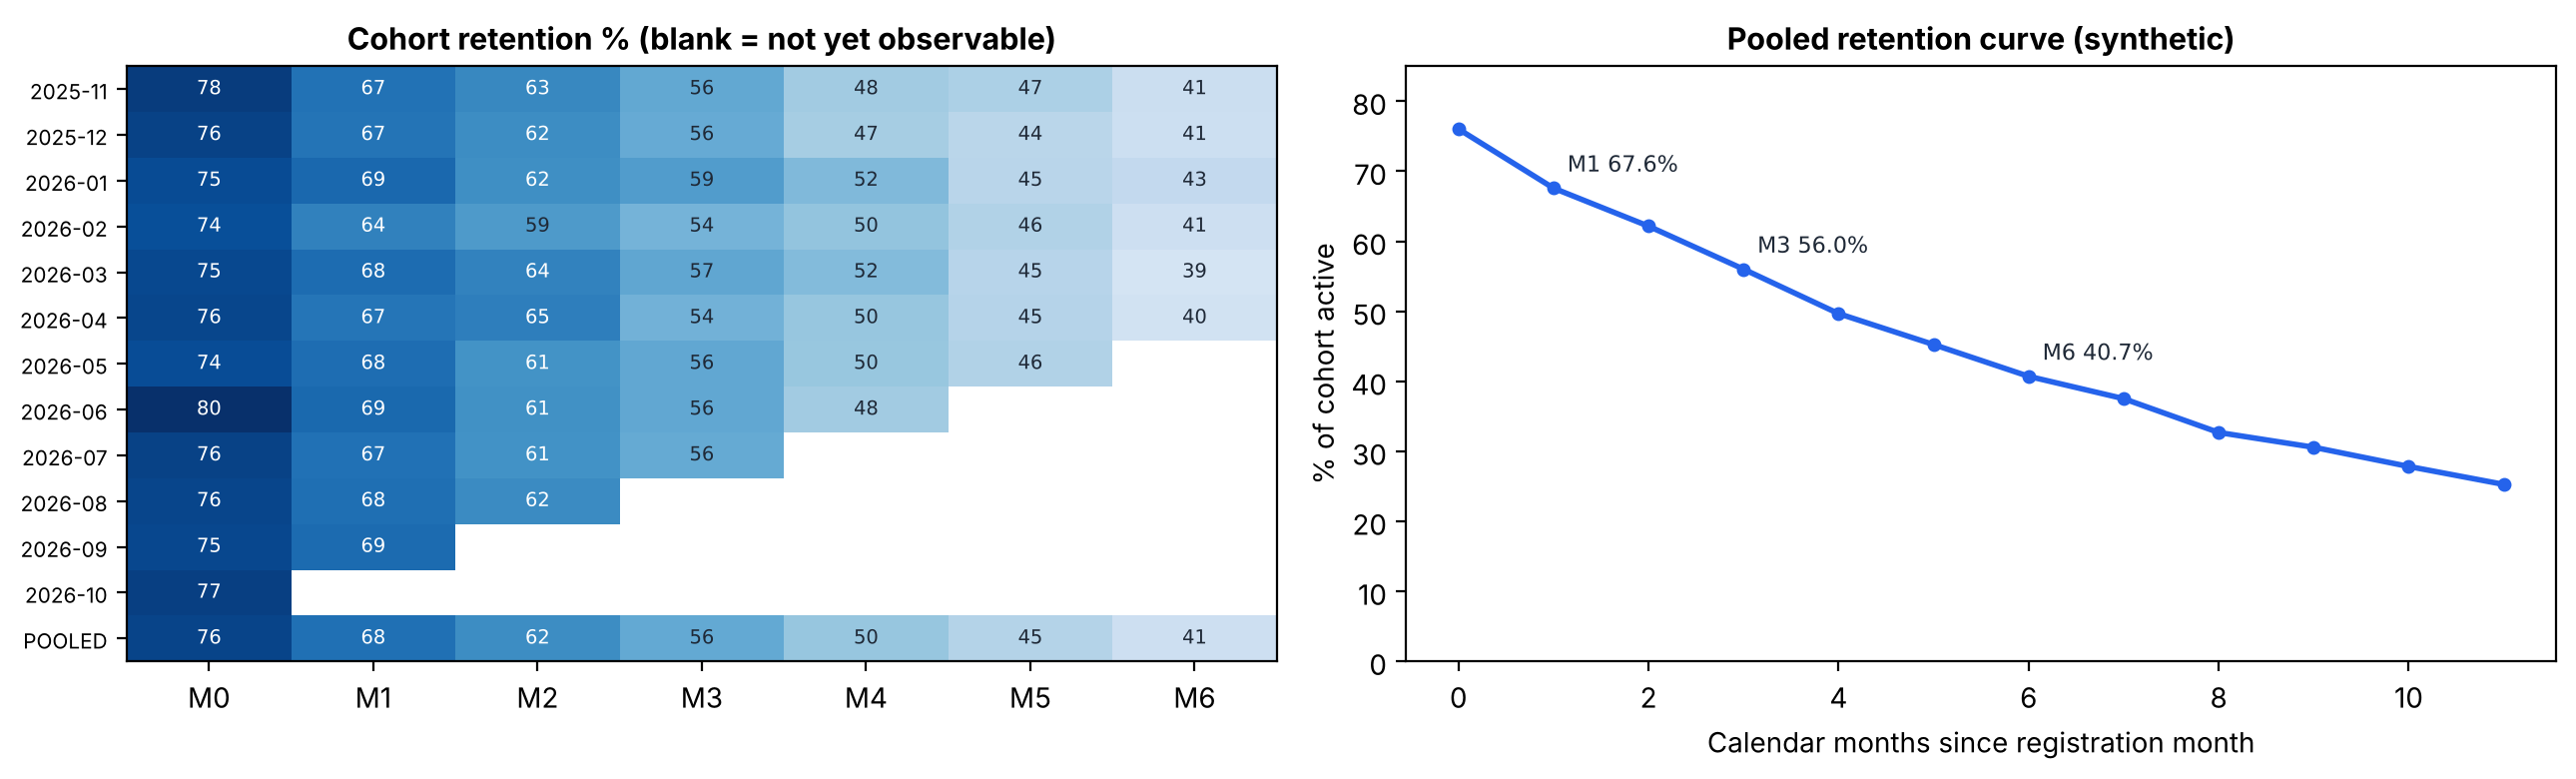

{'M1': 0.6758446687143485, 'M3': 0.5601291364003228, 'M6': 0.4070635721493441}

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4)); cohort.plot_retention_heatmap(mat, ax[0]); cohort.plot_retention_curve(act, ax[1]); plt.tight_layout(); plt.show()
cohort.retention_summary(act)

## 2 · MAU

In [4]:
mau = cohort.mau_table(users, act); mau

,activity_month,mau,mau_new,mau_existing,registered_to_date,mau_pct_of_registered
0,2025-11,642,642,0,827,77.6
1,2025-12,1225,670,555,1703,71.9
2,2026-01,1713,606,1107,2515,68.1
3,2026-02,2157,584,1573,3304,65.3
4,2026-03,2514,619,1895,4126,60.9
5,2026-04,2935,626,2309,4955,59.2
6,2026-05,3284,626,2658,5797,56.6
7,2026-06,3622,629,2993,6584,55.0
8,2026-07,3901,649,3252,7434,52.5
9,2026-08,4135,644,3491,8284,49.9


## 3 · Repeat trading and dormancy

In [5]:
print(cohort.repeat_trading(users)); print(cohort.dormancy_rate(users))

{'base_users': 7434, 'ever_traded_pct': np.float64(79.88969599139091), 'repeat_pct_of_traders': np.float64(69.28775888196667), 'repeat3_pct_of_traders': np.float64(49.031823539316385)}
{'eligible': 7434, 'dormant_3m_pct': np.float64(21.95318805488297)}


## 4 · Rule-based journey segments (Phase 3 rule)

In [6]:
segmentation.journey_summary(users)

,journey_segment,users,avg_tenure_days,avg_trading_value_6m_inr,tickets_per_user,share_pct
0,01 New / in-flight onboarding,601,11.12,6351.05,0.60,6.01
1,02 KYC-pending (stalled),2831,187.31,4408.67,1.00,28.31
2,03 Bank-link pending (stalled),818,194.92,4132.22,0.83,8.18
3,04 Deposit-pending (stalled),1333,194.95,4491.46,0.78,13.33
4,"05 Deposited, never traded (stalled)",881,196.56,3909.27,0.72,8.81
5,06 First-time trader (<=30d since first trade),317,38.93,17074.36,0.59,3.17
6,07 Repeat trader (2-3 trading months of last 6),1684,200.77,36730.05,0.58,16.84
7,08 High-engagement trader (>=4 trading months ...,896,210.12,61159.86,0.60,8.96
8,09 Inactive trader (no activity Aug-Oct),352,268.88,21908.34,0.59,3.52
9,10 Occasional trader (0-1 trading months of la...,287,184.02,13700.58,0.63,2.87


## 5 · K-means behavioural clusters (scikit-learn)
Features are standardised; the number of clusters follows a rule fixed *before* looking at results (k >= 3 with bootstrap stability ARI >= 0.85, then best silhouette). Cluster labels are descriptive, not causal.

In [7]:
km_u, sel, prof, K = segmentation.kmeans_segments(users)
print('chosen k =', K, '| users clustered =', len(km_u))
sel

chosen k = 4 | users clustered = 7496


,k,inertia,silhouette,bootstrap_stability_ari
0,2,31926.3012,0.3659,0.9923
1,3,25949.6002,0.3249,0.9799
2,4,22577.4152,0.3318,0.8511
3,5,19641.0189,0.2715,0.8901
4,6,17667.4934,0.2702,0.8185
5,7,16116.3381,0.2871,0.7721
6,8,15068.1714,0.2800,0.7246


In [8]:
prof

,cluster,activity_ratio,trade_months_6m,log_trading_value_6m,months_since_last_active,log_first_deposit,ticket_count,funnel_depth,size,share_pct,first_trade_rate_pct,dormant_3m_pct
0,0,0.488,0.000,0.000,1.137,1.564,0.919,1.139,1623,21.652,1.109,11.548
1,1,0.647,2.804,10.153,0.939,8.778,0.599,3.891,3116,41.569,89.089,11.316
2,2,0.557,1.359,8.761,1.126,0.000,0.915,0.690,1970,26.281,0.000,15.924
3,3,0.269,0.109,0.893,5.403,1.706,0.877,1.231,787,10.499,4.956,100.000


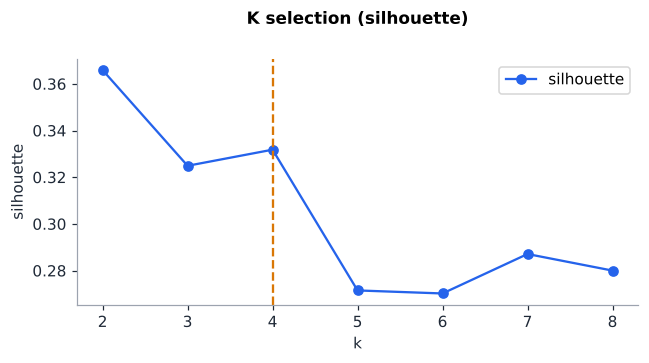

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.4)); ax.plot(sel.k, sel.silhouette, marker='o', color='#2563EB', label='silhouette'); ax.set_xlabel('k'); ax.set_ylabel('silhouette'); ax2 = ax.twiny(); ax.set_title('K selection (silhouette)'); ax2.set_visible(False)
ax.axvline(K, color='#D97706', ls='--'); ax.legend(); plt.tight_layout(); plt.show()